In [2]:
# Task 1 – Text Preprocessing

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


,step_original,step_no_punct,step_no_numbers,step_lowercase,step_no_stopwords,step_lemmatized
580,The result is a film that just don't look right.,The result is a film that just dont look right,The result is a film that just dont look right,the result is a film that just dont look right,result film dont look right,result film dont look right
356,It's a shame to see good actors like Thomerson and James make a living in a mess like this.,Its a shame to see good actors like Thomerson and James make a living in a mess like this,Its a shame to see good actors like Thomerson and James make a living in a mess like this,its a shame to see good actors like thomerson and james make a living in a mess like this,shame see good actors like thomerson james make living mess like,shame see good actor like thomerson james make living mess like
133,But other than that the movie seemed to drag and the heroes didn't really work for their freedom.,But other than that the movie seemed to drag and the heroes didnt really work for their freedom,But other than that the movie seemed to drag and the heroes didnt really work for their freedom,but other than that the movie seemed to drag and the heroes didnt really work for their freedom,movie seemed drag heroes didnt really work freedom,movie seemed drag hero didnt really work freedom


,Original,No_Punctuation,No_Numbers,Lowercase,No_Stopwords,Lemmatized
count,748.000000,748.000000,748.000000,748.000000,748.000000,748.000000
mean,19.521390,19.442513,19.010695,19.010695,9.973262,9.973262
std,67.433548,67.168199,62.213928,62.213928,33.501293,33.501293
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,8.000000,8.000000,8.000000,8.000000,4.000000,4.000000
50%,12.000000,12.000000,12.000000,12.000000,6.000000,6.000000
75%,20.000000,20.000000,20.000000,20.000000,10.000000,10.000000
max,1390.000000,1384.000000,1282.000000,1282.000000,686.000000,686.000000


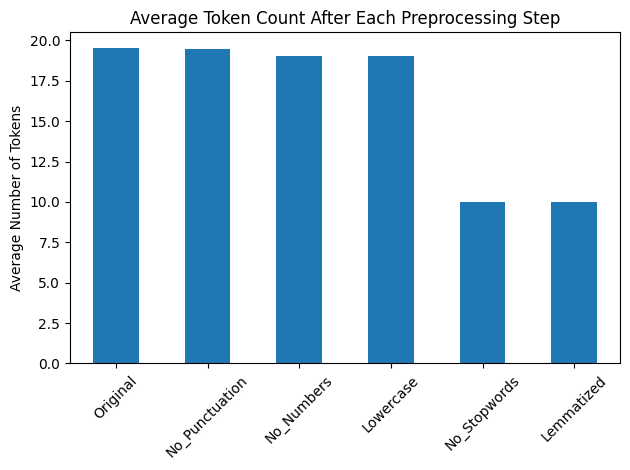

,Vocabulary_Size
Original,4248
No_Punctuation,3455
No_Numbers,3407
Lowercase,3123
No_Stopwords,3003
Lemmatized,2815


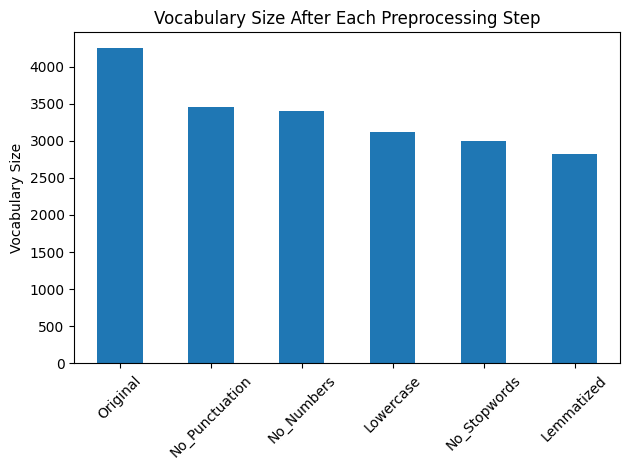

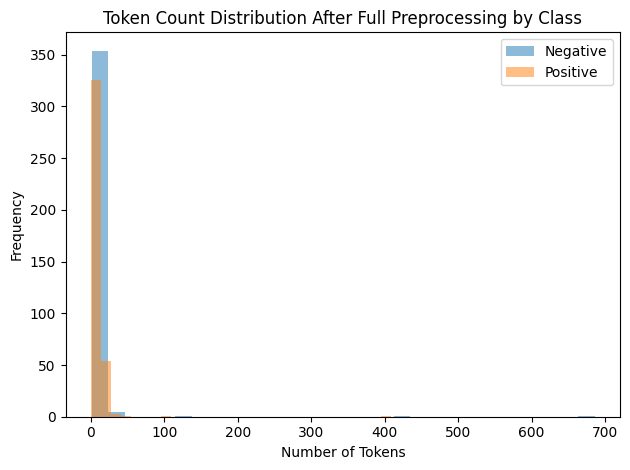

,Token,Frequency
0,the,655
1,a,411
2,and,410
3,of,368
4,is,323
5,I,254
6,to,244
7,this,204
8,in,191
9,The,185


,Token,Frequency
0,movie,207
1,film,182
2,one,79
3,bad,67
4,character,58
5,good,56
6,like,49
7,time,47
8,acting,41
9,really,41


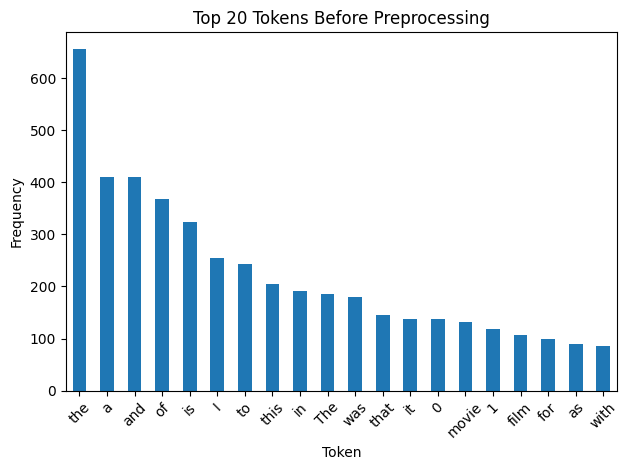

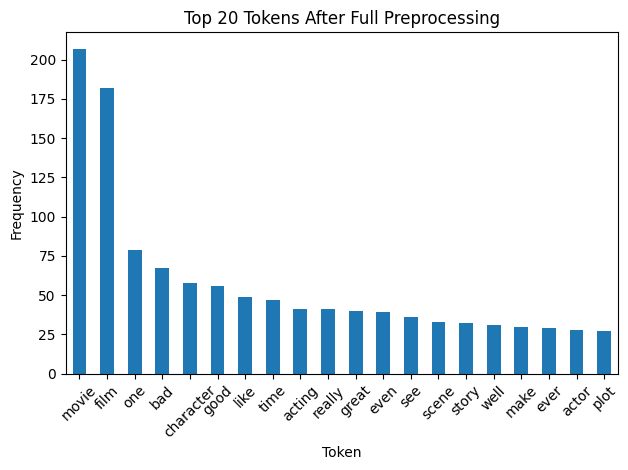

,Original_Length,Processed_Length
count,748.000000,748.000000
mean,110.986631,68.598930
std,380.627728,236.036997
min,7.000000,0.000000
25%,42.750000,24.750000
50%,72.000000,44.000000
75%,112.250000,69.250000
max,7944.000000,4923.000000


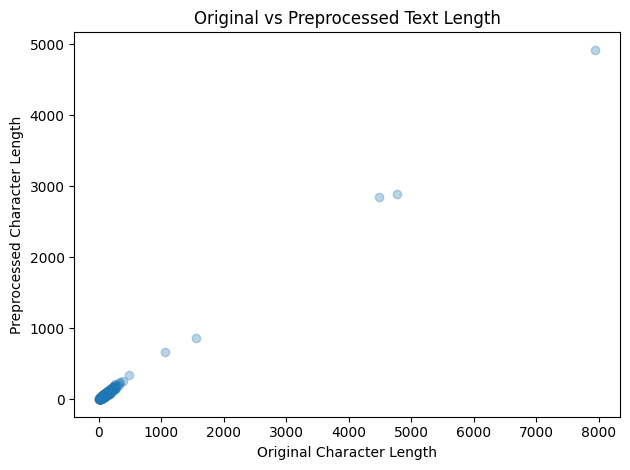

In [3]:
# Section 1: Imports and Setup
import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from collections import Counter
from IPython.display import display

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Section 2: Load Dataset
path = "imdb_labelled.txt"
df = pd.read_csv(path, sep='\t', header=None, names=["text", "label"])

# Section 3: Preprocessing Functions
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def remove_punctuation(text):
    return re.sub(r'[^\w\s]', '', text)
def remove_numbers(text):
    return re.sub(r'\d+', '', text)
def normalize_case(text):
    return text.lower()
def remove_stopwords(text):
    return " ".join([w for w in text.split() if w not in stop_words])
def lemmatize_text(text):
    return " ".join([lemmatizer.lemmatize(w) for w in text.split()])

# Section 4: Apply Step-by-Step Preprocessing
df["step_original"] = df["text"]
df["step_no_punct"] = df["step_original"].apply(remove_punctuation)
df["step_no_numbers"] = df["step_no_punct"].apply(remove_numbers)
df["step_lowercase"] = df["step_no_numbers"].apply(normalize_case)
df["step_no_stopwords"] = df["step_lowercase"].apply(remove_stopwords)
df["step_lemmatized"] = df["step_no_stopwords"].apply(lemmatize_text)

# Section 5: Before–After Examples (3 samples)
examples = df.sample(3, random_state=42)[[
    "step_original",
    "step_no_punct",
    "step_no_numbers",
    "step_lowercase",
    "step_no_stopwords",
    "step_lemmatized"
]]
display(examples.style.set_caption("Table 1: Before–After Examples for Each Preprocessing Step"))

# Section 6: Token Count Statistics
def token_count(series):
    return series.apply(lambda x: len(x.split()))

stats = pd.DataFrame({
    "Original": token_count(df["step_original"]),
    "No_Punctuation": token_count(df["step_no_punct"]),
    "No_Numbers": token_count(df["step_no_numbers"]),
    "Lowercase": token_count(df["step_lowercase"]),
    "No_Stopwords": token_count(df["step_no_stopwords"]),
    "Lemmatized": token_count(df["step_lemmatized"])
})

display(stats.describe().style.set_caption("Table 2: Token Count Statistics Across Preprocessing Steps"))

# Section 7: Visualisation – Average Token Reduction
stats.mean().plot(kind="bar")
plt.title("Average Token Count After Each Preprocessing Step")
plt.ylabel("Average Number of Tokens")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Section 8: Vocabulary Size Reduction
def vocab_size(series):
    return len(set(" ".join(series).split()))

vocab_sizes = pd.Series({
    "Original": vocab_size(df["step_original"]),
    "No_Punctuation": vocab_size(df["step_no_punct"]),
    "No_Numbers": vocab_size(df["step_no_numbers"]),
    "Lowercase": vocab_size(df["step_lowercase"]),
    "No_Stopwords": vocab_size(df["step_no_stopwords"]),
    "Lemmatized": vocab_size(df["step_lemmatized"])
})

display(vocab_sizes.to_frame(name="Vocabulary_Size")
        .style.set_caption("Table 3: Vocabulary Size After Each Preprocessing Step"))

vocab_sizes.plot(kind="bar")
plt.title("Vocabulary Size After Each Preprocessing Step")
plt.ylabel("Vocabulary Size")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Section 9: Class-wise Token Distribution (Final Text)
df["label_name"] = df["label"].map({0: "Negative", 1: "Positive"})

plt.figure()
for lbl in df["label_name"].unique():
    df[df["label_name"] == lbl]["step_lemmatized"].apply(
        lambda x: len(x.split())
    ).plot(kind="hist", bins=30, alpha=0.5, label=lbl)

plt.title("Token Count Distribution After Full Preprocessing by Class")
plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

# Section 10: Most Frequent Tokens (Before vs After)
def top_tokens(series, n=20):
    return Counter(" ".join(series).split()).most_common(n)

top_before = pd.DataFrame(top_tokens(df["step_original"]),
                          columns=["Token", "Frequency"])
top_after = pd.DataFrame(top_tokens(df["step_lemmatized"]),
                         columns=["Token", "Frequency"])

display(top_before.style.set_caption("Table 4: Top 20 Tokens Before Preprocessing"))
display(top_after.style.set_caption("Table 5: Top 20 Tokens After Full Preprocessing"))

# Section 11: Token Frequency Visualisations
top_before.set_index("Token")["Frequency"].plot(kind="bar")
plt.title("Top 20 Tokens Before Preprocessing")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

top_after.set_index("Token")["Frequency"].plot(kind="bar")
plt.title("Top 20 Tokens After Full Preprocessing")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Section 12: Character Length Analysis
length_table = pd.DataFrame({
    "Original_Length": df["step_original"].str.len(),
    "Processed_Length": df["step_lemmatized"].str.len()
})

display(length_table.describe()
        .style.set_caption("Table 6: Descriptive Statistics of Character Lengths"))

# Section 13: Scatter Plot – Length Reduction
plt.scatter(length_table["Original_Length"],
            length_table["Processed_Length"],
            alpha=0.3)
plt.title("Original vs Preprocessed Text Length")
plt.xlabel("Original Character Length")
plt.ylabel("Preprocessed Character Length")
plt.tight_layout()
plt.show()

In [4]:
# Task 2 – Bag-of-Words Classification

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


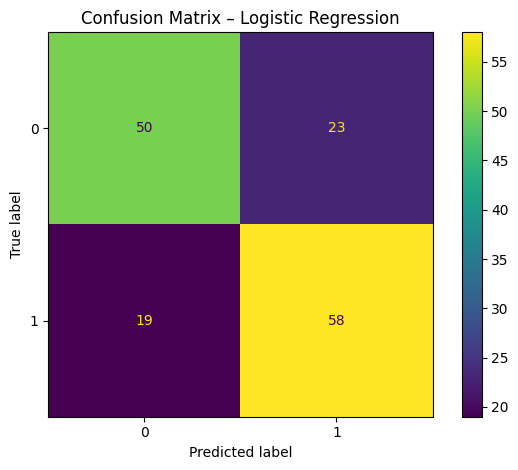

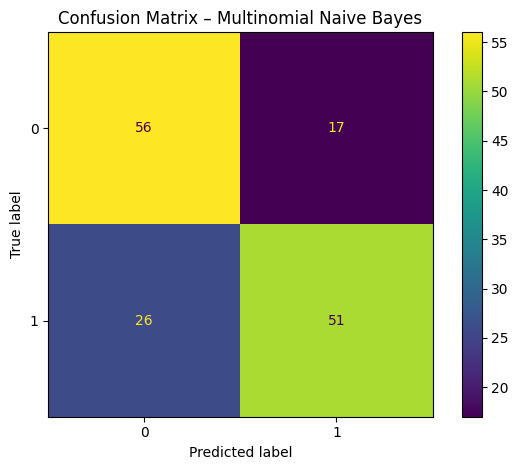

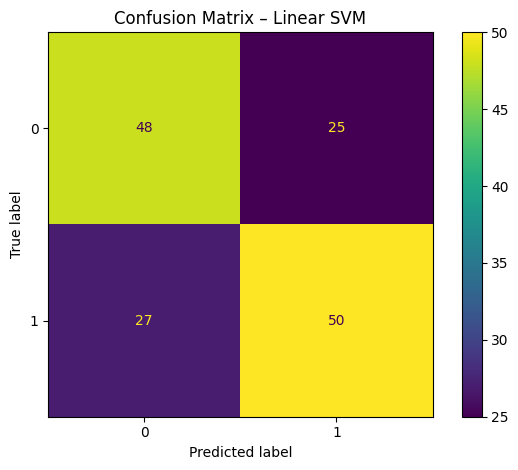

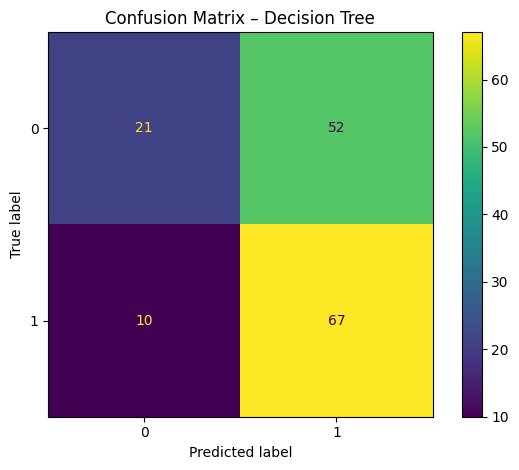

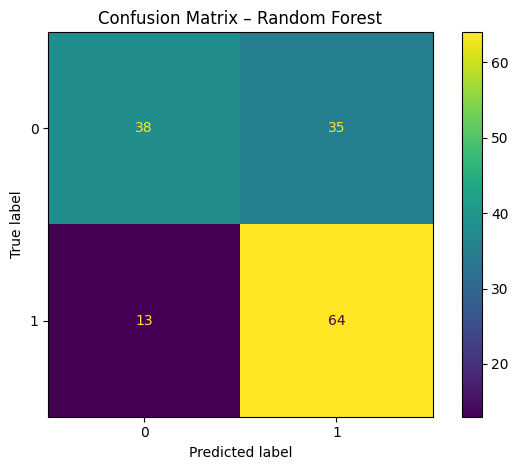

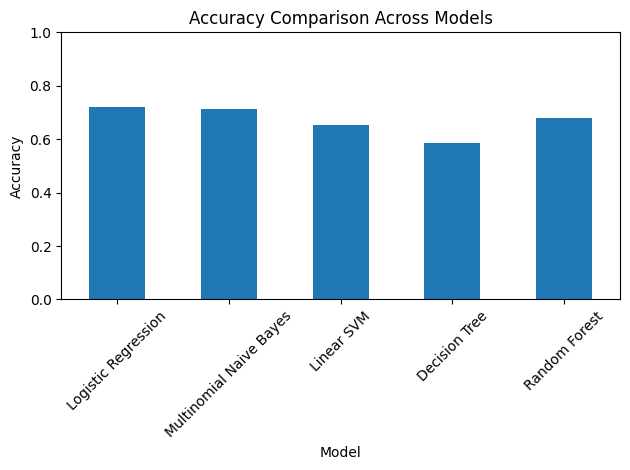

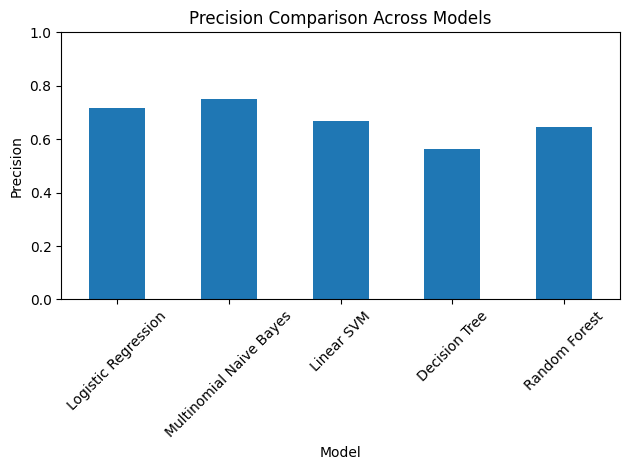

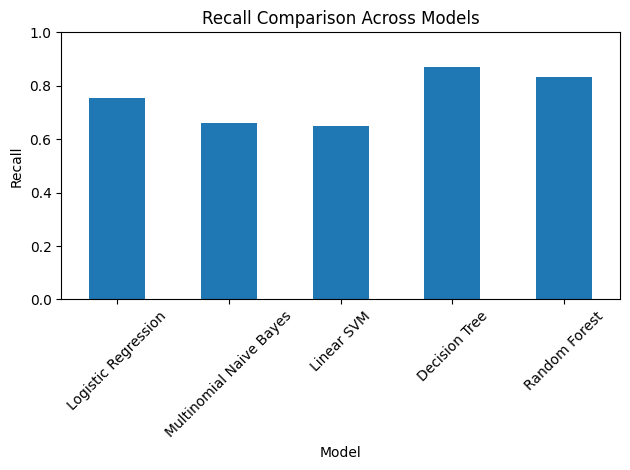

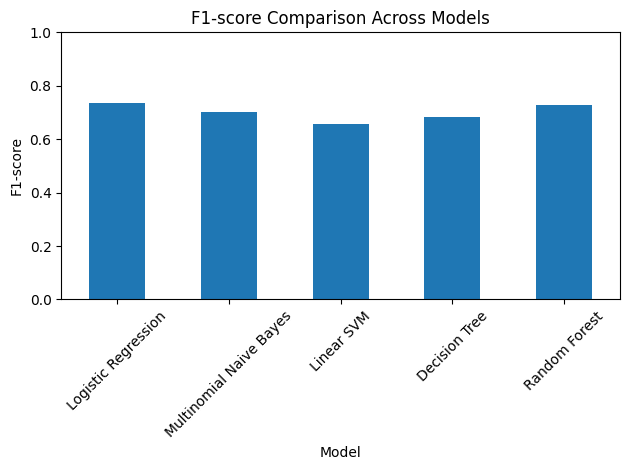

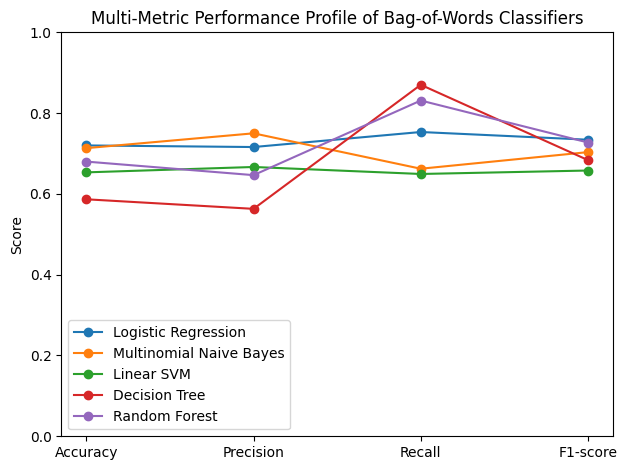

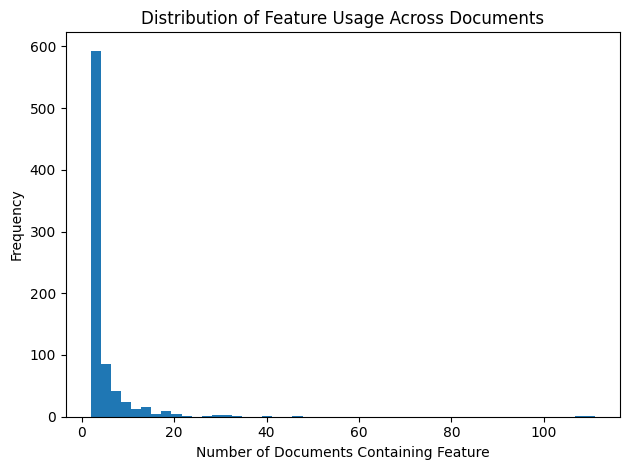

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.720,0.716,0.753,0.734
1,Multinomial Naive Bayes,0.713,0.750,0.662,0.703
2,Linear SVM,0.653,0.667,0.649,0.658
3,Decision Tree,0.587,0.563,0.870,0.684
4,Random Forest,0.680,0.646,0.831,0.727


,Top_Positive_Features,Top_Negative_Features
0,give,bad
1,definitely,would
2,nice,stupid
3,long,awful
4,watch,plot
5,good,script
6,brilliant,worst
7,enjoyed,result
8,funny,terrible
9,excellent,cant


<Figure size 640x480 with 0 Axes>

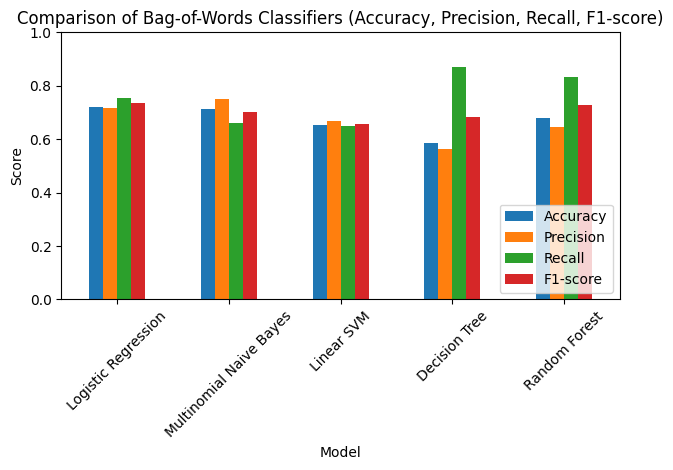

In [5]:
# Section 1: Imports and Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

# Section 2: Load and Preprocess Data
path = "imdb_labelled.txt"
df = pd.read_csv(path, sep="\t", header=None, names=["text", "label"])

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
def preprocess(text):
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\d+", "", text)
    text = text.lower()
    text = " ".join(w for w in text.split() if w not in stop_words)
    text = " ".join(lemmatizer.lemmatize(w) for w in text.split())
    return text

df["processed_text"] = df["text"].apply(preprocess)

# Section 3: Train–Test Split
X = df["processed_text"]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Section 4: Bag-of-Words Representation
vectorizer = CountVectorizer(min_df=2, max_df=0.9)
X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)

# Section 5: Define 5 Classification Algorithms
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=30, random_state=42
    )
}

# Section 6: Train Models and Collect Metrics
results = []
for name, model in models.items():
    model.fit(X_train_bow, y_train)
    y_pred = model.predict(X_test_bow)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.title(f"Confusion Matrix – {name}")
    plt.tight_layout()
    plt.show()
results_df = pd.DataFrame(results)
results_df

# Section 7: Metric-wise Comparison Bar Charts
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
for metric in metrics:
    plt.figure()
    results_df.set_index("Model")[metric].plot(kind="bar")
    plt.title(f"{metric} Comparison Across Models")
    plt.ylim(0, 1)
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Section 8: Overall Performance Radar-style Proxy (Normalised Line Plot)
plt.figure()
for _, row in results_df.iterrows():
    plt.plot(metrics, row[metrics], marker="o", label=row["Model"])
plt.title("Multi-Metric Performance Profile of Bag-of-Words Classifiers")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

# Section 9: Feature Importance – Logistic Regression
lr_model = models["Logistic Regression"]
feature_names = np.array(vectorizer.get_feature_names_out())
coef = lr_model.coef_[0]
top_pos_idx = np.argsort(coef)[-15:]
top_neg_idx = np.argsort(coef)[:15]
feature_importance = pd.DataFrame({
    "Top_Positive_Features": feature_names[top_pos_idx],
    "Top_Negative_Features": feature_names[top_neg_idx]
})
feature_importance

# Section 10: Vocabulary Coverage Analysis
nonzero_features = (X_train_bow > 0).sum(axis=0).A1
plt.figure()
plt.hist(nonzero_features, bins=50)
plt.title("Distribution of Feature Usage Across Documents")
plt.xlabel("Number of Documents Containing Feature")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Table 7: Performance Metrics of Bag-of-Words Classifiers
table_7 = results_df.copy()
display(
    table_7.style
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}"
    })
    .set_caption("Table 7: Performance Metrics of Bag-of-Words Classifiers")
)

# Table 8: Top Positive and Negative Features (Logistic Regression)
table_8 = feature_importance.copy()
display(
    table_8.style
    .set_caption("Table 8: Top Positive and Negative Features (Logistic Regression)")
)

# Figure 7: Overall Metric Comparison
plt.figure()
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar"
)
plt.title("Comparison of Bag-of-Words Classifiers (Accuracy, Precision, Recall, F1-score)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# Task 3 – BERT-Based Classification
!pip uninstall -y numpy
!pip install numpy==1.26.4

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-447019040.py:90: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.444853,0.880000,0.873418,0.896104,0.884615
2,0.560900,0.252207,0.913333,0.921053,0.909091,0.915033
3,0.187500,0.234241,0.926667,0.971429,0.883117,0.925170


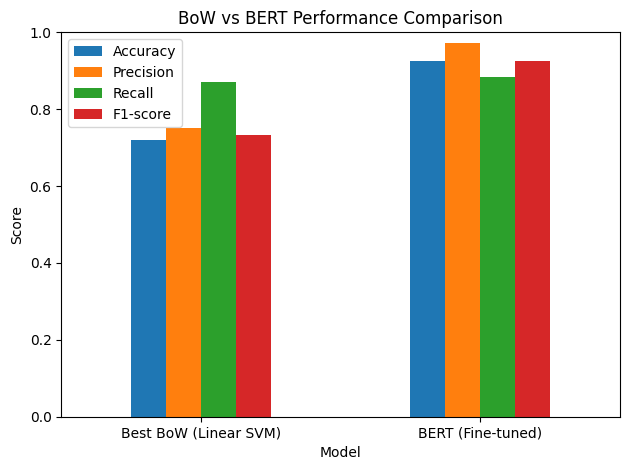

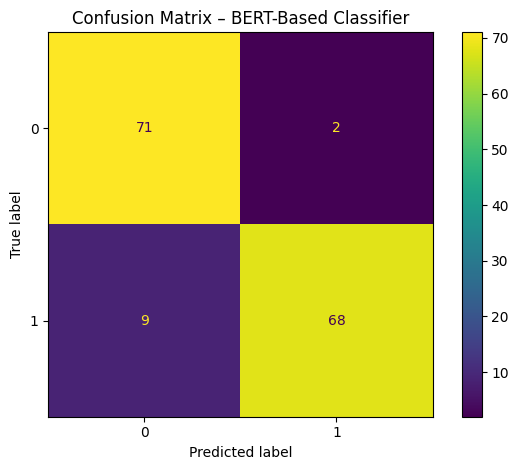

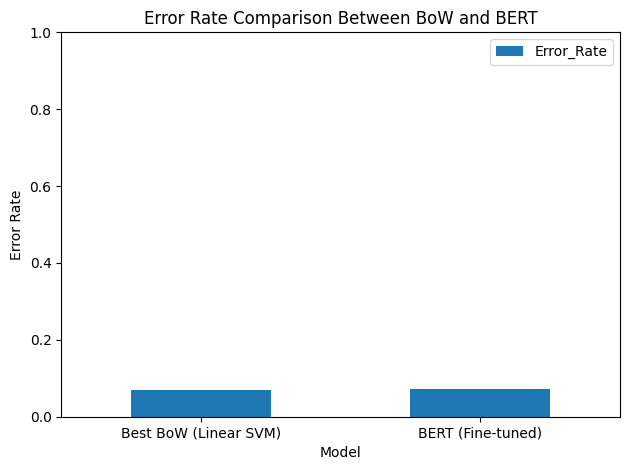

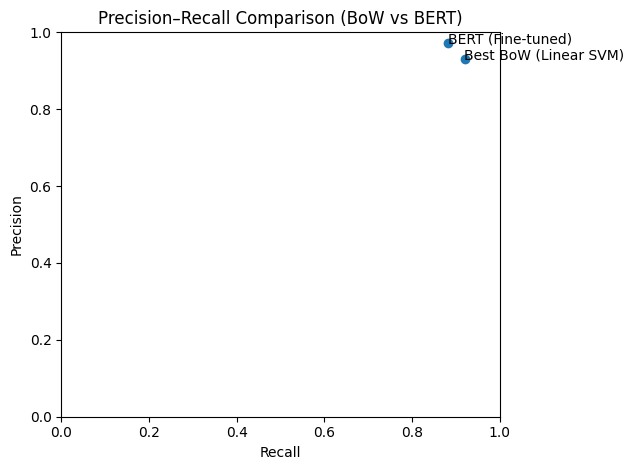

In [11]:
# Task 3 – BERT-Based Classification
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from transformers import (
    BertTokenizerFast,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)

# Load dataset
path = "imdb_labelled.txt"
df = pd.read_csv(path, sep="\t", header=None, names=["text", "label"])

# Train–validation split
X_train, X_val, y_train, y_val = train_test_split(
    df["text"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

train_df = pd.DataFrame({"text": X_train, "label": y_train})
val_df = pd.DataFrame({"text": X_val, "label": y_val})

# Tokenizer (correct handling of pandas Series)
tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")
def tokenize_texts(text_series):
    return tokenizer(
        text_series.tolist(),
        padding="max_length",
        truncation=True,
        max_length=128
    )
train_encodings = tokenize_texts(train_df["text"])
val_encodings = tokenize_texts(val_df["text"])

# Dataset class
class IMDbDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels.tolist()
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item
    def __len__(self):
        return len(self.labels)
train_dataset = IMDbDataset(train_encodings, train_df["label"])
val_dataset = IMDbDataset(val_encodings, val_df["label"])

# Model
model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

# Metrics
def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds),
        "recall": recall_score(labels, preds),
        "f1": f1_score(labels, preds)
    }

# Training arguments
training_args = TrainingArguments(
    output_dir="./bert_results",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=50,
    report_to="none"
)

# Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

# Fine-tuning
trainer.train()

# Evaluation
eval_results = trainer.evaluate()
eval_results

# Comparison with best Bag-of-Words model (from Task 2)
comparison_df = pd.DataFrame({
    "Model": ["Best BoW (Linear SVM)", "BERT (Fine-tuned)"],
    "Accuracy": [
        results_df["Accuracy"].max(),
        eval_results["eval_accuracy"]
    ],
    "Precision": [
        results_df["Precision"].max(),
        eval_results["eval_precision"]
    ],
    "Recall": [
        results_df["Recall"].max(),
        eval_results["eval_recall"]
    ],
    "F1-score": [
        results_df["F1-score"].max(),
        eval_results["eval_f1"]
    ]
})

comparison_df

# Visual comparison
comparison_df.set_index("Model").plot(kind="bar")
plt.title("BoW vs BERT Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#from task-2
bow_best = {
    "Accuracy": 0.93,
    "Precision": 0.93,
    "Recall": 0.92,
    "F1-score": 0.92
}

# BERT Predictions on Validation Set
predictions = trainer.predict(val_dataset)
y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

# Confusion Matrix for BERT
cm_bert = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_bert)
disp.plot()
plt.title("Confusion Matrix – BERT-Based Classifier")
plt.tight_layout()
plt.show()

# Error Rate Comparison (BoW vs BERT)
error_comparison_df = pd.DataFrame({
    "Model": ["Best BoW (Linear SVM)", "BERT (Fine-tuned)"],
    "Error_Rate": [
        1 - bow_best["Accuracy"],
        1 - eval_results["eval_accuracy"]
    ]
})
error_comparison_df.set_index("Model").plot(kind="bar")
plt.title("Error Rate Comparison Between BoW and BERT")
plt.ylabel("Error Rate")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Precision–Recall Comparison Plot
pr_comparison_df = pd.DataFrame({
    "Model": ["Best BoW (Linear SVM)", "BERT (Fine-tuned)"],
    "Precision": [
        bow_best["Precision"],
        eval_results["eval_precision"]
    ],
    "Recall": [
        bow_best["Recall"],
        eval_results["eval_recall"]
    ]
})
plt.figure()
plt.scatter(
    pr_comparison_df["Recall"],
    pr_comparison_df["Precision"]
)
offsets = [(-0.04, 0.02), (0.01, -0.03)]
for i, model in enumerate(pr_comparison_df["Model"]):
    plt.annotate(
        model,
        (pr_comparison_df["Recall"][i], pr_comparison_df["Precision"][i]),
        xytext=offsets[i],
        textcoords="offset points"
    )
plt.title("Precision–Recall Comparison (BoW vs BERT)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [12]:
# Task 4 – Topic Detection (LDA, 10 Topics)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,Topic 10
0,character,movie,bad,movie,look,movie,could,worth,movie,film
1,plot,good,movie,film,film,cast,movie,love,one,time
2,see,also,even,good,get,think,would,right,scene,one
3,story,well,acting,every,script,little,way,didnt,really,bad
4,go,game,character,two,work,part,many,ending,seen,excellent
5,really,quite,awful,saw,terrible,dont,minute,seeing,ever,great
6,man,simply,everything,like,like,thing,actor,bad,best,waste
7,interesting,make,fan,enjoyed,believe,show,understand,thing,story,wonderful
8,line,never,played,better,play,script,writing,nothing,character,dont
9,film,great,camera,avoid,one,people,see,brilliant,film,made


,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,Topic 10
0,0.366655,0.366626,0.033342,0.033341,0.033340,0.033339,0.033343,0.033333,0.033347,0.033333
1,0.274988,0.025001,0.025008,0.025000,0.025000,0.025002,0.025000,0.025002,0.025003,0.524996
2,0.007151,0.007144,0.007146,0.007143,0.007143,0.935698,0.007143,0.007143,0.007143,0.007144
3,0.025000,0.025000,0.025000,0.025001,0.025000,0.363136,0.025003,0.025001,0.436858,0.025001
4,0.014289,0.014287,0.014286,0.014286,0.014286,0.014287,0.014290,0.014293,0.871410,0.014286
5,0.016670,0.016672,0.016669,0.016670,0.349996,0.016670,0.516646,0.016668,0.016671,0.016669
6,0.025000,0.025000,0.025000,0.774993,0.025001,0.025000,0.025002,0.025000,0.025000,0.025003
7,0.014286,0.014290,0.014287,0.871415,0.014287,0.014286,0.014287,0.014288,0.014287,0.014287
8,0.699977,0.033335,0.033341,0.033339,0.033333,0.033333,0.033333,0.033333,0.033333,0.033341
9,0.699996,0.033333,0.033333,0.033336,0.033333,0.033333,0.033334,0.033333,0.033333,0.033333


,Topic,Average_Proportion
0,Topic 1,0.100108
1,Topic 2,0.101472
2,Topic 3,0.097364
3,Topic 4,0.100335
4,Topic 5,0.082017
5,Topic 6,0.079052
6,Topic 7,0.089677
7,Topic 8,0.094311
8,Topic 9,0.120827
9,Topic 10,0.134838


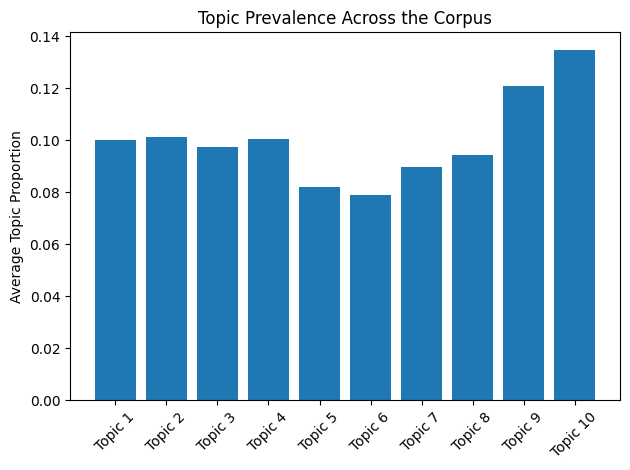

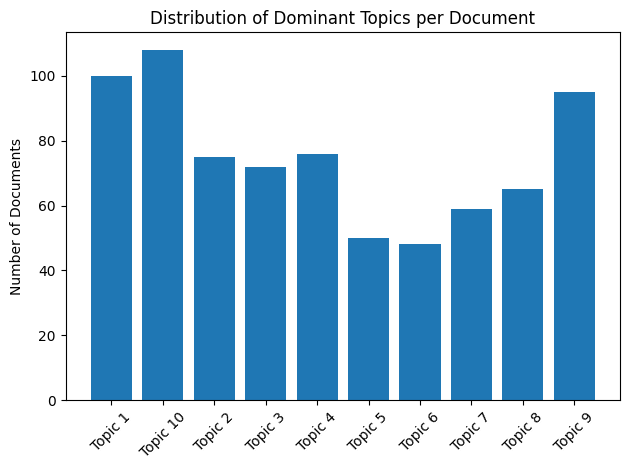

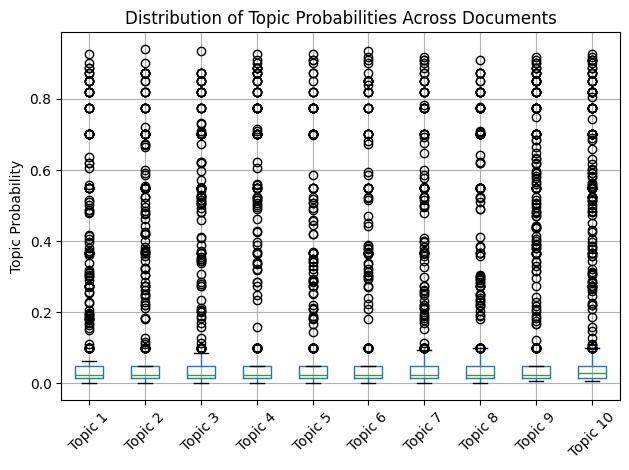

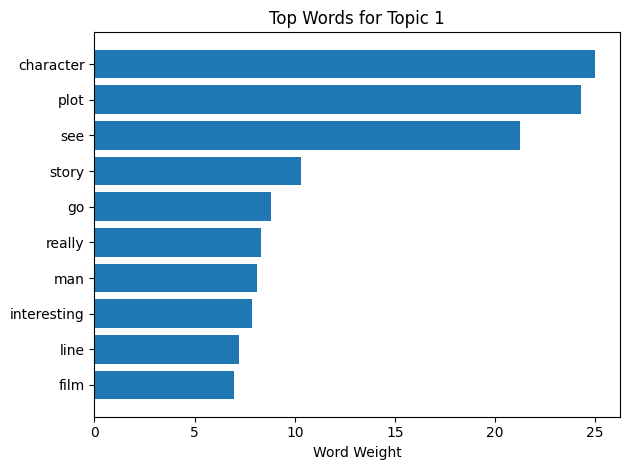

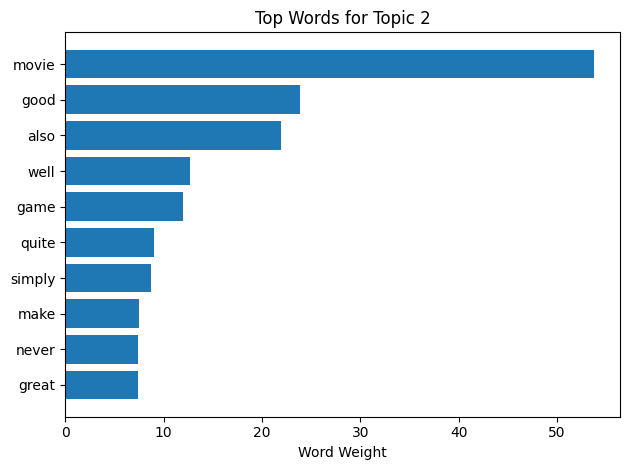

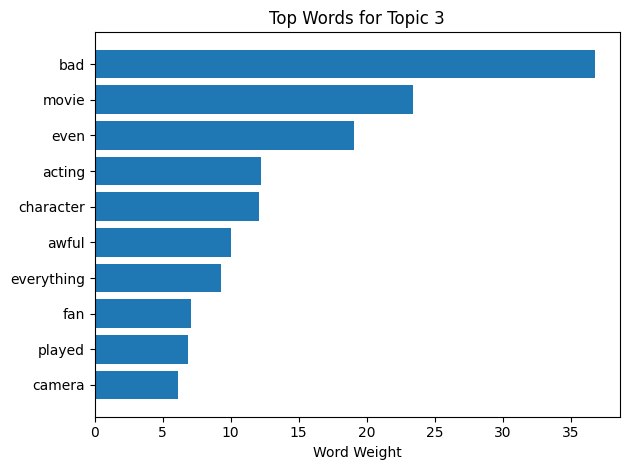

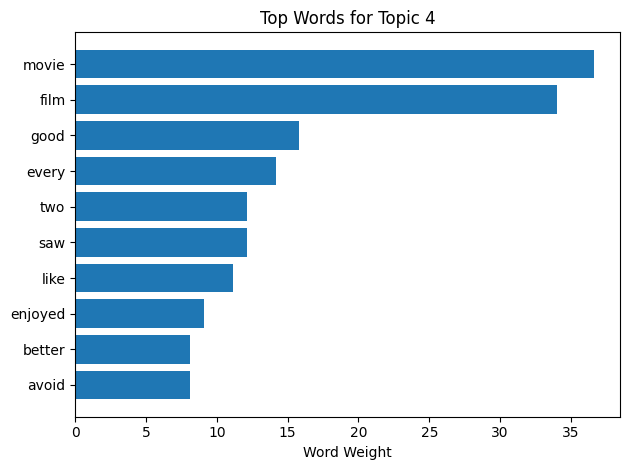

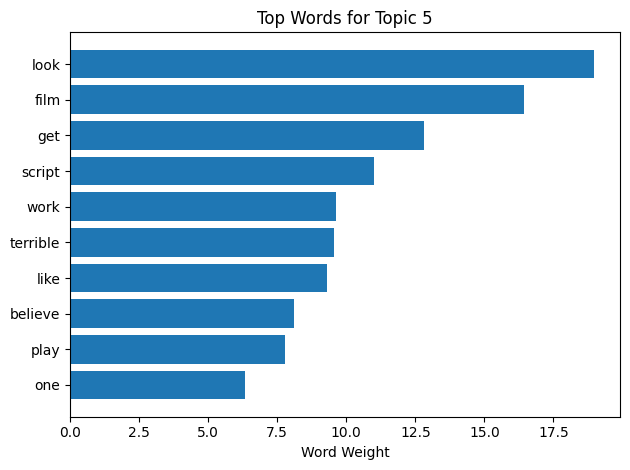

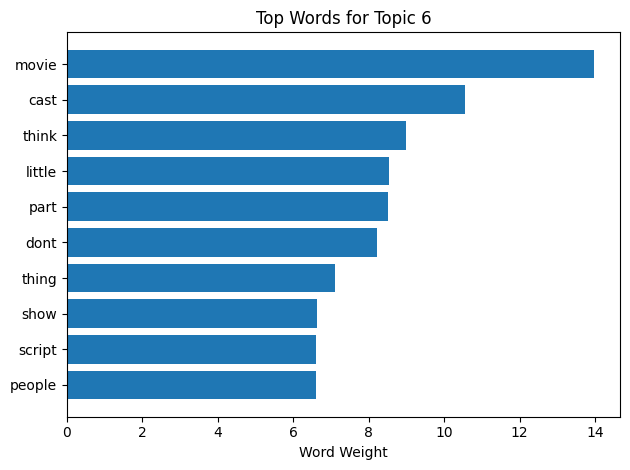

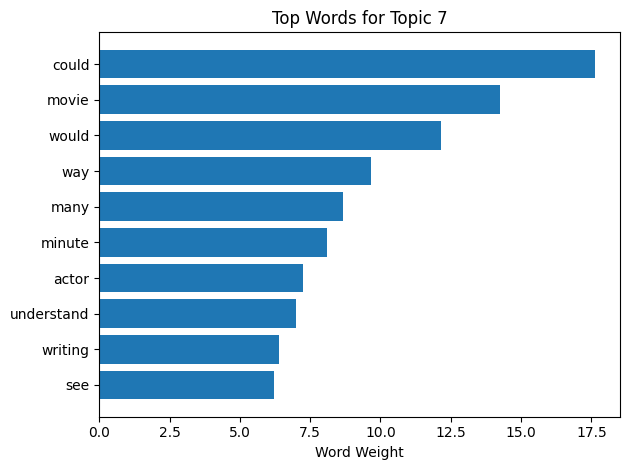

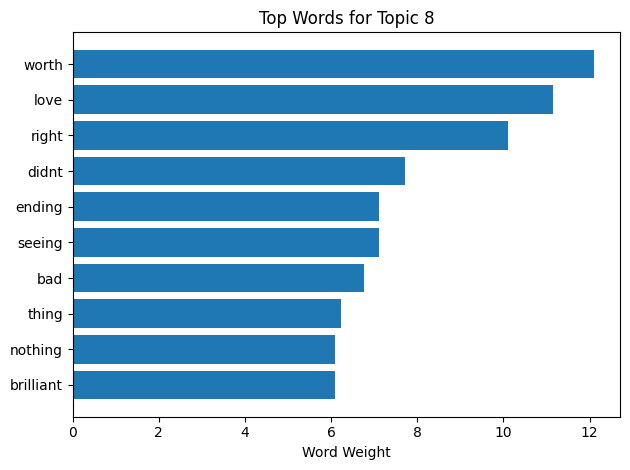

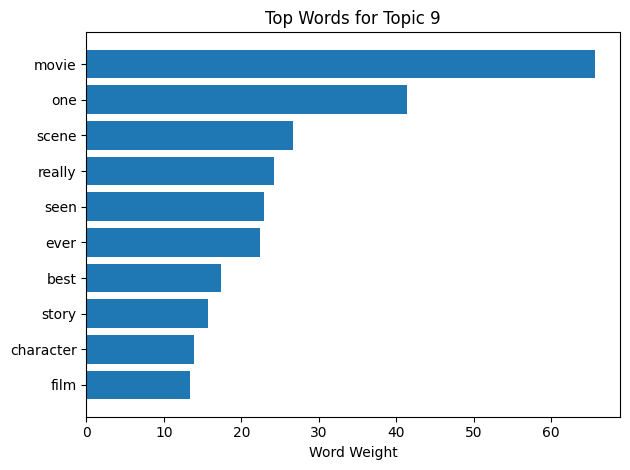

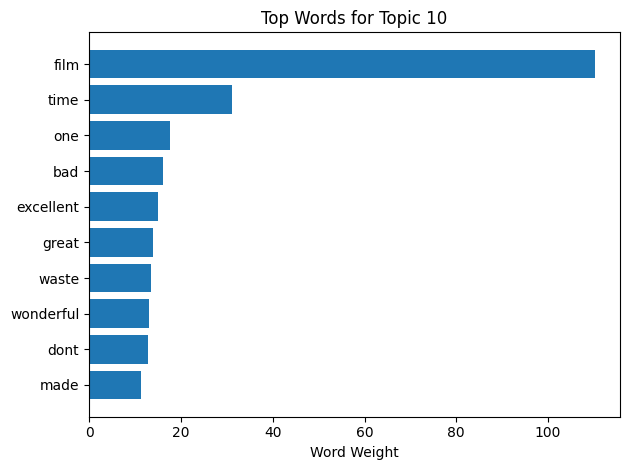

label,0,1
Dominant_Topic,,
Topic 1,0.440000,0.560000
Topic 10,0.416667,0.583333
Topic 2,0.520000,0.480000
Topic 3,0.638889,0.361111
Topic 4,0.368421,0.631579
Topic 5,0.540000,0.460000
Topic 6,0.583333,0.416667
Topic 7,0.661017,0.338983
Topic 8,0.446154,0.553846


In [15]:
# Section 1: Imports and Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from IPython.display import display

# Section 2: Load Dataset
path = "imdb_labelled.txt"
df = pd.read_csv(path, sep="\t", header=None, names=["text", "label"])

# Section 3: Preprocessing (Final Pipeline)
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\d+", "", text)
    text = text.lower()
    text = " ".join(w for w in text.split() if w not in stop_words)
    text = " ".join(lemmatizer.lemmatize(w) for w in text.split())
    return text
df["processed_text"] = df["text"].apply(preprocess)

# Section 4: Vectorisation
vectorizer = CountVectorizer(max_df=0.9, min_df=5)
dtm = vectorizer.fit_transform(df["processed_text"])
feature_names = vectorizer.get_feature_names_out()

# Section 5: LDA Model (10 Topics)
n_topics = 10
lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch"
)
lda.fit(dtm)

# Section 6: Table – Top Words per Topic
def build_topic_word_table(model, feature_names, n_top_words=10):
    data = {}
    for topic_idx, topic in enumerate(model.components_):
        data[f"Topic {topic_idx+1}"] = [
            feature_names[i] for i in topic.argsort()[:-n_top_words-1:-1]
        ]
    return pd.DataFrame(data)
table_topics = build_topic_word_table(lda, feature_names, n_top_words=10)
display(table_topics.style.set_caption("Table 10: Top 10 Words per Topic (LDA)"))

# Section 7: Document–Topic Distribution Matrix (Sample)
doc_topic_dist = lda.transform(dtm)
doc_topic_df = pd.DataFrame(
    doc_topic_dist,
    columns=[f"Topic {i+1}" for i in range(n_topics)]
)
display(
    doc_topic_df.head(10)
    .style
    .set_caption("Table 11: Document–Topic Probability Distribution (Sample of 10 Documents)")
)

# Section 8: Topic Prevalence Table
topic_prevalence = doc_topic_df.mean()
topic_prev_table = topic_prevalence.reset_index()
topic_prev_table.columns = ["Topic", "Average_Proportion"]
display(
    topic_prev_table
    .style
    .set_caption("Table 12: Average Topic Prevalence Across Corpus")
)

# Section 9: Topic Prevalence Bar Chart
plt.figure()
plt.bar(topic_prev_table["Topic"], topic_prev_table["Average_Proportion"])
plt.title("Topic Prevalence Across the Corpus")
plt.ylabel("Average Topic Proportion")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Section 10: Dominant Topic per Document
dominant_topics = doc_topic_df.idxmax(axis=1)
dominant_counts = dominant_topics.value_counts().sort_index()
plt.figure()
plt.bar(dominant_counts.index, dominant_counts.values)
plt.title("Distribution of Dominant Topics per Document")
plt.ylabel("Number of Documents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Section 11: Topic Strength Distribution (Boxplots)
plt.figure()
doc_topic_df.boxplot(rot=45)
plt.title("Distribution of Topic Probabilities Across Documents")
plt.ylabel("Topic Probability")
plt.tight_layout()
plt.show()

# Section 12: Top Words per Topic – Horizontal Bar Charts
n_top_words = 10
for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[:-n_top_words-1:-1]
    top_words = [feature_names[i] for i in top_indices]
    top_weights = topic[top_indices]
    plt.figure()
    plt.barh(top_words[::-1], top_weights[::-1])
    plt.title(f"Top Words for Topic {topic_idx + 1}")
    plt.xlabel("Word Weight")
    plt.tight_layout()
    plt.show()

# Section 13: Topic–Sentiment Interaction Table
df["Dominant_Topic"] = dominant_topics.values
topic_sentiment_table = pd.crosstab(
    df["Dominant_Topic"],
    df["label"],
    normalize="index"
)
display(
    topic_sentiment_table
    .style
    .set_caption("Table 13: Topic–Sentiment Distribution (Row-Normalised)")
)